# Routing

In [1]:
%matplotlib inline
from IPython.display import display
import pandas as pd

from dualde import load_example
from dualde.contacts import attach_minimum_distance
from dualde.path_tests import (
    result_record,
    test_path_vs_contact_decoys,
    test_path_vs_rsa_matched_contact_decoys,
    test_path_vs_rsa_matched_sets,
)
from dualde.routing import run_information_transfer_pipeline
from dualde.structure_graph import build_contact_graph, residue_distance_map, residue_rsa_map

EXAMPLE, cfg = load_example()
OUT = EXAMPLE / "outputs"
LIGAND_NAMES = list(cfg["ligand_names"])
coup_path = next((EXAMPLE / "couplings").glob("*CouplingScoresCompared_all.csv"))

deconv = pd.read_csv(OUT / "deconvolution.csv")
contacts = pd.read_csv(OUT / "contacts.csv")
scores = attach_minimum_distance(deconv, contacts)
result = run_information_transfer_pipeline(
    all_merged_df=scores,
    couplings_file=str(coup_path),
    functional_residues_file=str(OUT / "functional_residues.csv"),
    active_site_ligands=LIGAND_NAMES,
    activity_wt=cfg["activity_wt"],
    abundance_wt=cfg["abundance_wt"],
    score_col=cfg["score_col"],
    low_score_percentile=cfg["low_score_percentile"],
    prob_threshold=cfg["prob_threshold"],
    n_paths=cfg["n_paths"],
    weighted=True,
    dist_cutoff=cfg["dist_cutoff"],
    functional_dist_cutoff=cfg["functional_dist_cutoff"],
    seq_len=cfg["seq_len"],
    verbose=False,
)
paths, pairs = result["paths_df"], result["pairs_df"]
paths.to_csv(OUT / "coupling_paths.csv", index=False)
pairs.to_csv(OUT / "coupling_pairs.csv", index=False)
print(len(paths), "paths", int((pairs["n_paths_found"] > 0).sum()), "pairs")
display(paths.nsmallest(8, "n_edges")[["source", "target", "path_rank", "n_edges", "path_str"]])


372 paths 76 pairs


,source,target,path_rank,n_edges,path_str
161,49,51,1,1,49 -> 51
186,83,82,5,1,83 -> 82
287,116,113,1,1,116 -> 113
25,16,82,1,2,16 -> 56 -> 82
95,45,15,1,2,45 -> 17 -> 15
135,47,15,1,2,47 -> 17 -> 15
155,48,66,1,2,48 -> 63 -> 66
183,83,82,2,2,83 -> 81 -> 82


156 residues 721 contacts 156 RSA


,test,statistic,alternative,agg,observed,null_mean,null_sd,p_value,n_null,n_unique_null,n_repeated_draws,activity_wt,abundance_wt,score_col,rsa_tol,z
0,contact,both_low,greater,mean,0.416959,0.159839,0.147496,0.066933,1000,1000,0,0.45,0.45,None,NaN,1.743229
1,contact_rsa,both_low,greater,mean,0.416959,0.238001,0.140537,0.115884,1000,1000,0,0.45,0.45,None,0.1,1.273389
2,rsa_sets,both_low,greater,mean,0.416959,0.235727,0.100459,0.033966,1000,1000,0,0.45,0.45,None,0.1,1.804033


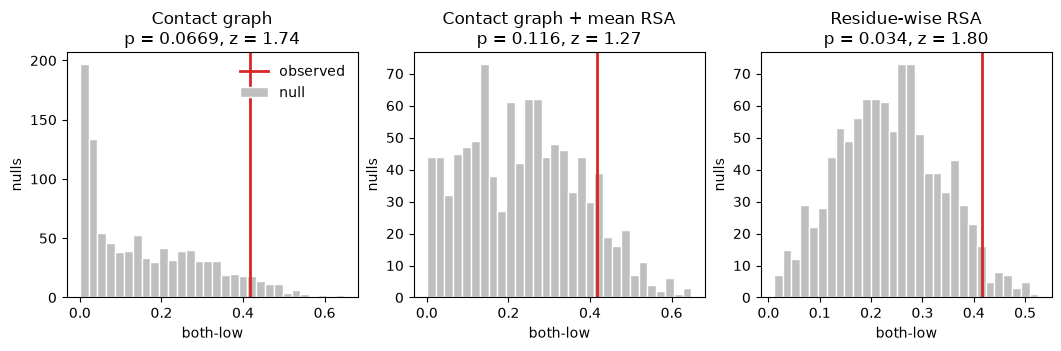

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

pdb_path = EXAMPLE / "pdb" / f"{cfg['pdb_id']}_cleaned.pdb"
dist = residue_distance_map(pdb_path, chain_id=cfg["chain"], atom="CA")
scored = set(scores["target_pos"].dropna().astype(int))
rsa_map = {
    int(pos): round(float(value), 3)
    for pos, value in residue_rsa_map(pdb_path, chain_id=cfg["chain"], cap_at_monomer=False).items()
    if int(pos) in scored
}
contact = build_contact_graph(dist, cutoff=8.0)
print(contact.number_of_nodes(), "residues", contact.number_of_edges(), "contacts", len(rsa_map), "RSA")

PATH = [15, 17, 18, 60, 97, 56, 82]
PATH_RSA = [47, 17, 18, 60, 97, 56, 82]
common = dict(
    df=scores,
    n_null=1000,
    seed=0,
    rsa_map=rsa_map,
    exclude_endpoints=True,
    statistic="both_low",
    alternative="greater",
    activity_wt=cfg["activity_wt"],
    abundance_wt=cfg["abundance_wt"],
    verbose=False,
)
results = {
    "contact": test_path_vs_contact_decoys(
        PATH, dist_df=dist, cutoff=8.0, match_buriedness=False, **common
    ),
    "contact_rsa": test_path_vs_rsa_matched_contact_decoys(
        PATH_RSA, dist_df=dist, cutoff=8.0, rsa_tol=0.1, **common
    ),
    "rsa_sets": test_path_vs_rsa_matched_sets(PATH, rsa_tol=0.1, **common),
}
rows = []
for res in results.values():
    row = result_record(res)
    null = res["null_stats"]
    row["z"] = float((res["observed"] - null.mean()) / null.std())
    row["path"] = " -> ".join(map(str, res["observed_path"]))
    rows.append(row)
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "path_null_tests.csv", index=False)
display(summary.drop(columns=["path"]))

titles = ["Contact graph", "Contact graph + mean RSA", "Residue-wise RSA"]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), constrained_layout=True)
for ax, res, title in zip(axes, results.values(), titles):
    ax.hist(res["null_stats"], bins=30, color="0.75", edgecolor="white")
    ax.axvline(res["observed"], color="C3", lw=2)
    z = (res["observed"] - res["null_stats"].mean()) / res["null_stats"].std()
    ax.set_title(f"{title}\np = {res['p_value']:.3g}, z = {z:.2f}")
    ax.set_xlabel("both-low")
    ax.set_ylabel("nulls")
axes[0].legend(
    handles=[
        Line2D([0], [0], color="C3", lw=2, label="observed"),
        Patch(facecolor="0.75", edgecolor="white", label="null"),
    ],
    frameon=False,
)
fig.savefig(OUT / "path_null_tests.png", dpi=150)
plt.show()
